<a href="https://colab.research.google.com/github/ReyAndrey22/Machine-Learning-Laboratories/blob/main/Laborator_6_%C3%8Env%C4%83%C8%9Bare_automat%C4%83.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Laboratoare_Învățare_automată/Lab6/Country-data.csv")

In [ ]:
print(df.head())
print(df.info())

               country  child_mort  exports  health  imports  income  \
0          Afghanistan        90.2     10.0    7.58     44.9    1610   
1              Albania        16.6     28.0    6.55     48.6    9930   
2              Algeria        27.3     38.4    4.17     31.4   12900   
3               Angola       119.0     62.3    2.85     42.9    5900   
4  Antigua and Barbuda        10.3     45.5    6.03     58.9   19100   

   inflation  life_expec  total_fer   gdpp  
0       9.44        56.2       5.82    553  
1       4.49        76.3       1.65   4090  
2      16.10        76.5       2.89   4460  
3      22.40        60.1       6.16   3530  
4       1.44        76.8       2.13  12200  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-nul

In [ ]:
median_gdpp = df['gdpp'].median()
df['is_rich'] = (df['gdpp'] > median_gdpp).astype(int)

In [ ]:
X = df.drop(columns=['country', 'gdpp', 'is_rich'])
y = df['is_rich']

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [ ]:
n_components = X_train.shape[1]
accuracy_scores = []
n_features_list = range(1, n_components + 1)

for k in n_features_list:
    pca = PCA(n_components=k)
    X_train_pca = pca.fit_transform(X_train)
    X_test_pca = pca.transform(X_test)

    model = LogisticRegression(random_state=42)
    model.fit(X_train_pca, y_train)

    y_pred = model.predict(X_test_pca)
    accuracy = accuracy_score(y_test, y_pred)
    accuracy_scores.append(accuracy)

Accuracy at each step: [0.8529411764705882, 0.9117647058823529, 0.9117647058823529, 0.8529411764705882, 0.8823529411764706, 0.8823529411764706, 0.8823529411764706, 0.8823529411764706]
Highest accuracy score: 0.9117647058823529
Optimal number of components for maximum score: 2


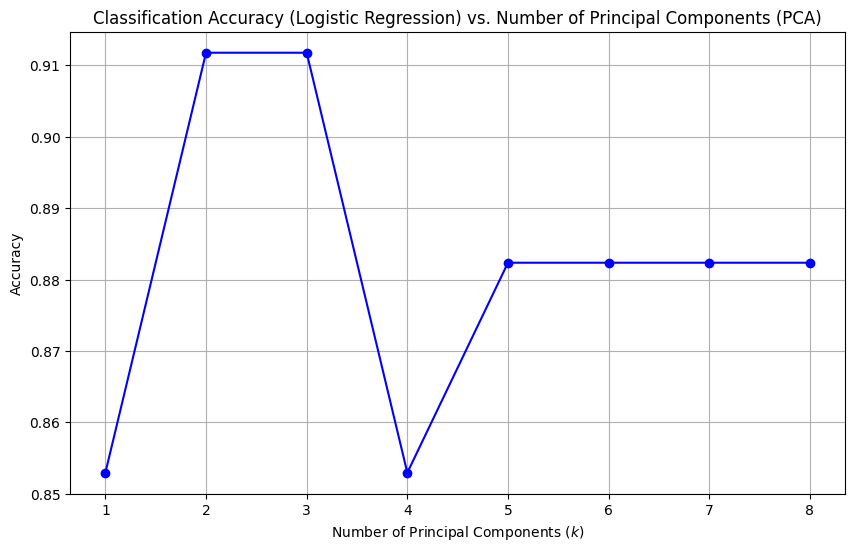

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(n_features_list, accuracy_scores, marker='o', linestyle='-', color='b')
plt.title('Classification Accuracy (Logistic Regression) vs. Number of Principal Components (PCA)')
plt.xlabel('Number of Principal Components ($k$)')
plt.ylabel('Accuracy')
plt.xticks(n_features_list)
plt.grid(True)

print("Accuracy at each step:", accuracy_scores)
print("Highest accuracy score:", max(accuracy_scores))
print("Optimal number of components for maximum score:", n_features_list[np.argmax(accuracy_scores)])